# Building an Expected Goals (xG) Model from StatsBomb Open Data

**Author:** Anthony Adusei-Poku · MSc Data Science (University of East London, 2025)

**Question:** how likely is a given shot to become a goal, using only what is known at the moment the shot is struck?

Expected goals (xG) is the most widely used metric in modern football analytics. It underpins
recruitment, opposition analysis, match reporting and betting markets. In this notebook I:

1. Build a shot-level dataset of **~58,000 men's shots** from StatsBomb's free open data (big-five leagues 2015/16, World Cups 2018 and 2022, Euro 2020 and 2024, Copa América 2024, AFCON 2023 and the La Liga Messi seasons).
2. Engineer features describing shot geometry, technique, the type of assist and the defensive context from StatsBomb's freeze frames.
3. Train a **logistic regression** baseline and a **LightGBM** gradient-boosting model, evaluated on matches the models never saw.
4. Benchmark them against **StatsBomb's own professional xG model**.
5. Use the model to answer football questions: who finishes better than expected, and what did the 2022 World Cup final look like in xG terms?

> **Data:** StatsBomb Open Data, © StatsBomb, used under the [StatsBomb Open Data licence](https://github.com/statsbomb/open-data/blob/master/LICENSE.pdf). Thanks to StatsBomb for making it freely available.

In [1]:
# --- Setup -----------------------------------------------------------------
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score
import lightgbm as lgb
import shap
from mplsoccer import Pitch, VerticalPitch

warnings.filterwarnings("ignore")
sys.path.insert(0, "src")
from features import load_shots

SEED = 42
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
RES_DIR = "results"; os.makedirs(RES_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})
PALETTE = {"Distance + angle LR": "#9e9e9e", "Logistic regression": "#1f77b4",
           "LightGBM": "#d62728", "StatsBomb xG": "#2ca02c"}
def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), facecolor="white")

## 1. Data

`src/download_data.py` pulls each competition's match list and event files from the StatsBomb open-data
GitHub repository and keeps only the **Shot** events plus the pass that set each shot up (the *key pass*).
`src/features.py` turns these into one row per shot. Raw data is not committed to the repository; run the
download script to recreate it.

In [2]:
if not os.path.exists("data/shots") or not os.listdir("data/shots"):
    import subprocess; subprocess.run([sys.executable, "src/download_data.py"], check=True)

shots = load_shots("data/shots")
print(f"{len(shots):,} shots from {shots.match_id.nunique():,} matches, "
      f"{shots.player_id.nunique():,} players")

summary = (shots.groupby("competition")
           .agg(matches=("match_id", "nunique"), shots=("shot_id", "size"),
                goals=("is_goal", "sum"))
           .assign(conversion=lambda d: (d.goals / d.shots).round(3))
           .sort_values("shots", ascending=False))
summary

58,576 shots from 2,351 matches, 3,863 players


,matches,shots,goals,conversion
competition,,,,
Serie A 2015/16,380,9998,951,0.095
Premier League 2015/16,380,9908,988,0.100
La Liga 2015/16,380,9168,1014,0.111
Ligue 1 2015/16,377,8814,916,0.104
FIFA World Cup 2018,64,1706,183,0.107
FIFA World Cup 2022,64,1494,195,0.131
UEFA Euro 2024,51,1340,126,0.094
UEFA Euro 2020,51,1289,155,0.120
African Cup of Nations 2023,52,1244,159,0.128


### Penalties and shoot-outs are handled separately

Penalties are a fixed situation (same distance, same angle, only the keeper to beat), so they would teach the
model nothing about shot quality and would distort the distance/angle relationship. Shoot-out kicks
(period 5) are not part of open play at all. I therefore model **non-penalty shots only** and treat penalties
as a constant value equal to their observed conversion rate, the same approach most public xG models take.

In [3]:
pens = shots[shots.shot_type == "Penalty"]
pen_table = (pens.assign(situation=np.where(pens.period == 5, "Shoot-out", "In-game"))
             .groupby("situation").agg(penalties=("is_goal", "size"), scored=("is_goal", "sum"),
                                       conversion=("is_goal", "mean"),
                                       mean_statsbomb_xg=("statsbomb_xg", "mean")).round(3))
display(pen_table)
PEN_XG = pens.loc[pens.period != 5, "is_goal"].mean()   # in-game penalty value used later

np_shots = shots[(shots.shot_type != "Penalty") & (shots.period != 5)].reset_index(drop=True)
print(f"Non-penalty shots used for modelling: {len(np_shots):,} "
      f"(goal rate {np_shots.is_goal.mean():.3f})")

,penalties,scored,conversion,mean_statsbomb_xg
situation,,,,
In-game,671,510,0.760,0.783
Shoot-out,241,165,0.685,0.784


Non-penalty shots used for modelling: 57,664 (goal rate 0.101)


## 2. Feature engineering

| Group | Features |
|---|---|
| **Geometry** | distance to the centre of goal, the angle subtended by the posts (how much of the goal the shooter can see), raw x/y |
| **Technique** | body part (foot/head/other), technique (volley, lob, overhead, ...), first-time, one-on-one, open goal, follows a dribble, aerial won |
| **Situation** | shot type (open play vs direct free kick), play pattern (counter, corner, throw-in, ...), under pressure |
| **Assist** | type of key pass: through ball, cross, cut-back, high pass, set-piece delivery, ground pass or unassisted |
| **Defensive context (freeze frame)** | outfield opponents inside the shooter-to-posts triangle, opponents within 3 yards, goalkeeper distance from goal and whether he is in the shooting cone |

The freeze frame is a snapshot of every visible player's position at the moment of the shot and is available
for ~99% of shots. Missing values are imputed (median) and flagged with `has_freeze_frame`.

In [4]:
np_shots["log_distance"] = np.log1p(np_shots["distance"])

NUM = ["distance", "log_distance", "angle", "x", "y", "n_def_in_cone", "n_opp_within_3",
       "gk_dist_to_goal", "gk_in_cone"]
BIN = ["under_pressure", "first_time", "one_on_one", "open_goal", "follows_dribble",
       "aerial_won", "has_freeze_frame"]
CAT = ["body_group", "shot_type", "technique", "play_pattern", "assist_type"]
FEATURES = NUM + BIN + CAT
for c in CAT:
    np_shots[c] = np_shots[c].astype("category")
y = np_shots["is_goal"].values
np_shots[FEATURES].head()

,distance,log_distance,angle,x,y,n_def_in_cone,n_opp_within_3,gk_dist_to_goal,gk_in_cone,under_pressure,...,one_on_one,open_goal,follows_dribble,aerial_won,has_freeze_frame,body_group,shot_type,technique,play_pattern,assist_type
0,11.002272,2.485096,0.646009,110.1,35.2,0.0,0.0,7.247068,1.0,0,...,0,0,0,0,1,Foot,Open Play,Normal,From Counter,Ground/low pass
1,10.020978,2.399801,0.509810,114.1,48.1,3.0,1.0,3.492850,1.0,0,...,0,0,0,0,1,Foot,Open Play,Volley,From Corner,Set-piece pass
2,25.200992,3.265797,0.308957,95.3,45.0,2.0,0.0,1.166190,1.0,0,...,0,0,0,0,1,Foot,Free Kick,Normal,From Free Kick,Unassisted
3,26.840268,3.326483,0.181952,103.8,61.4,0.0,0.0,4.272002,1.0,0,...,0,0,0,0,1,Foot,Open Play,Normal,From Corner,Cut-back
4,28.229417,3.375176,0.242054,95.9,54.7,3.0,0.0,2.340940,1.0,0,...,0,0,0,0,1,Foot,Free Kick,Normal,From Free Kick,Unassisted


### What drives goal probability? A first look

Before modelling, the raw conversion rates already show the shape of the problem: conversion falls off
sharply with distance, headers convert far less often than footed shots from the same range, and each
extra defender in the shooting lane matters.

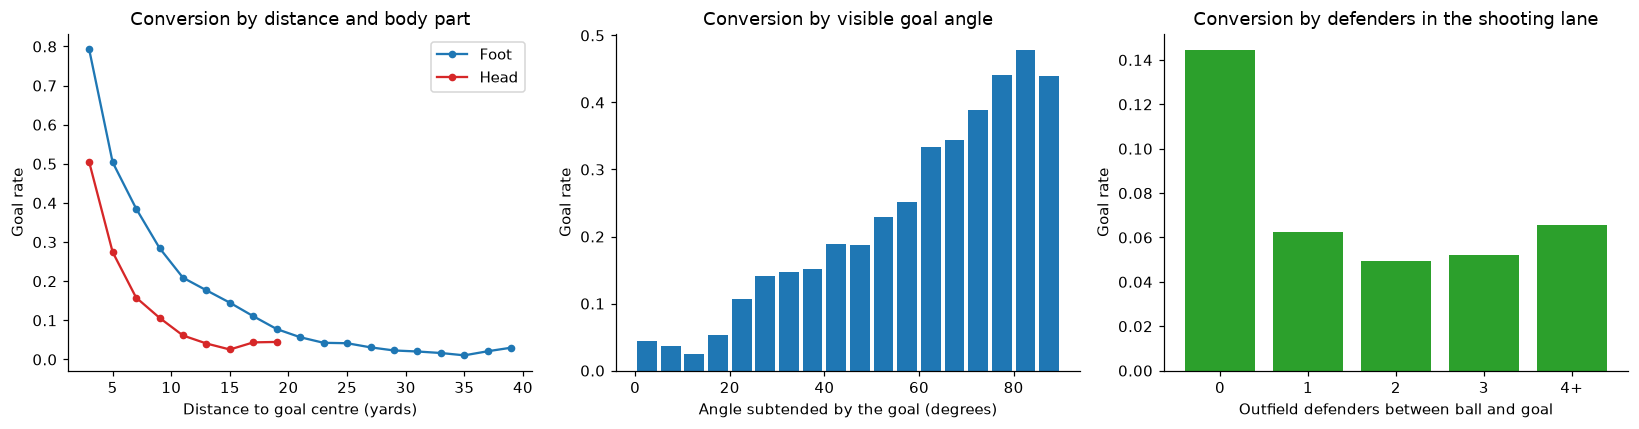

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
d = np_shots.assign(dist_bin=pd.cut(np_shots.distance, np.arange(0, 42, 2)))
rate = d.groupby(["dist_bin", "body_group"], observed=True).is_goal.agg(["mean", "size"]).reset_index()
rate = rate[rate["size"] >= 30]
rate["mid"] = rate.dist_bin.apply(lambda b: b.mid).astype(float)
for bg, col in [("Foot", "#1f77b4"), ("Head", "#d62728")]:
    r = rate[rate.body_group == bg]
    axes[0].plot(r.mid, r["mean"], "o-", color=col, label=bg, ms=4)
axes[0].set(xlabel="Distance to goal centre (yards)", ylabel="Goal rate",
            title="Conversion by distance and body part"); axes[0].legend()

a = np_shots.assign(angle_deg=np.degrees(np_shots.angle))
a["angle_bin"] = pd.cut(a.angle_deg, np.arange(0, 95, 5))
ar = a.groupby("angle_bin", observed=True).is_goal.agg(["mean", "size"]).reset_index()
ar = ar[ar["size"] >= 30]
axes[1].bar(ar.angle_bin.apply(lambda b: b.mid).astype(float), ar["mean"], width=4.2, color="#1f77b4")
axes[1].set(xlabel="Angle subtended by the goal (degrees)", ylabel="Goal rate",
            title="Conversion by visible goal angle")

cr = (np_shots.assign(n=np_shots.n_def_in_cone.clip(upper=4))
      .groupby("n").is_goal.agg(["mean", "size"]).reset_index())
axes[2].bar(cr.n.astype(int).astype(str).str.replace("4", "4+"), cr["mean"], color="#2ca02c")
axes[2].set(xlabel="Outfield defenders between ball and goal", ylabel="Goal rate",
            title="Conversion by defenders in the shooting lane")
fig.tight_layout(); save(fig, "01_eda_conversion.png"); plt.show()

## 3. Train/test split by match

Shots from the same match share conditions (teams, game state, weather), so splitting shots at random
would leak information. I hold out **20% of matches** as a test set using `GroupShuffleSplit`; a further
15% of the training matches is held back for early stopping of the boosting model. All headline metrics are
on the untouched test matches.

In [6]:
groups = np_shots["match_id"].values
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(gss.split(np_shots, y, groups))
train, test = np_shots.iloc[train_idx], np_shots.iloc[test_idx]
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
fit_i, val_i = next(gss_val.split(train, train.is_goal, train.match_id))
fit, val = train.iloc[fit_i], train.iloc[val_i]
print(f"train {len(train):,} shots / {train.match_id.nunique():,} matches "
      f"(of which {len(val):,} shots used for early stopping)")
print(f"test  {len(test):,} shots / {test.match_id.nunique():,} matches")
print(f"goal rate train {train.is_goal.mean():.3f}, test {test.is_goal.mean():.3f}")

train 46,079 shots / 1,880 matches (of which 6,912 shots used for early stopping)
test  11,585 shots / 471 matches
goal rate train 0.101, test 0.100


## 4. Models

* **Distance + angle LR**: the textbook two-feature xG model, as a naive reference point.
* **Logistic regression (full)**: all features, standardised numerics and one-hot categoricals. Interpretable and well calibrated by construction.
* **LightGBM**: gradient-boosted trees that can learn non-linearities and interactions (e.g. headers lose value with distance faster than footed shots). Early stopping on the validation matches.

In [7]:
def make_lr(num, binf, cat):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("bin", "passthrough", binf),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cat)])
    return Pipeline([("pre", pre), ("lr", LogisticRegression(max_iter=2000, C=1.0))])

lr_simple = make_lr(["distance", "angle"], [], []).fit(train, train.is_goal)
lr_full = make_lr(NUM, BIN, CAT).fit(train, train.is_goal)

lgb_params = dict(objective="binary", learning_rate=0.03, num_leaves=31, min_child_samples=80,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                  n_estimators=3000, random_state=SEED, verbose=-1)
gbm = lgb.LGBMClassifier(**lgb_params)
gbm.fit(fit[FEATURES], fit.is_goal, eval_set=[(val[FEATURES], val.is_goal)],
        eval_metric="binary_logloss", callbacks=[lgb.early_stopping(100, verbose=False)])
BEST_ITER = gbm.best_iteration_
print("LightGBM best iteration:", BEST_ITER)

preds = pd.DataFrame({
    "Distance + angle LR": lr_simple.predict_proba(test)[:, 1],
    "Logistic regression": lr_full.predict_proba(test)[:, 1],
    "LightGBM": gbm.predict_proba(test[FEATURES], num_iteration=BEST_ITER)[:, 1],
    "StatsBomb xG": test.statsbomb_xg.values,
}, index=test.index)

LightGBM best iteration: 157


## 5. Results on held-out matches

* **Log loss**: penalises confident wrong predictions; the main metric for probabilistic forecasts (lower is better).
* **Brier score**: mean squared error of the probability (lower is better).
* **ROC AUC**: how well the model ranks goals above non-goals (higher is better).

Confidence intervals come from a 1,000-sample bootstrap over **test matches** (so they respect the grouping).

In [8]:
yt = test.is_goal.values
rows = []
for name, p in preds.items():
    rows.append({"model": name, "log_loss": log_loss(yt, p), "brier": brier_score_loss(yt, p),
                 "roc_auc": roc_auc_score(yt, p), "total_xG": p.sum(), "actual_goals": yt.sum()})
metrics = pd.DataFrame(rows).set_index("model")

# Match-level bootstrap for 95% CIs on log loss and Brier
rng = np.random.default_rng(SEED)
mid = test.match_id.values
uniq, inv = np.unique(mid, return_inverse=True)
n_per = np.bincount(inv)
B = 1000
boot_idx = rng.integers(0, len(uniq), size=(B, len(uniq)))
for name, p in preds.items():
    p = np.clip(p.values, 1e-6, 1 - 1e-6)
    ll = -(yt * np.log(p) + (1 - yt) * np.log(1 - p)); br = (p - yt) ** 2
    ll_m, br_m = np.bincount(inv, ll), np.bincount(inv, br)
    cnt = n_per[boot_idx].sum(1)
    for metric, arr in [("log_loss", ll_m), ("brier", br_m)]:
        s = arr[boot_idx].sum(1) / cnt
        metrics.loc[name, f"{metric}_ci"] = f"[{np.percentile(s, 2.5):.4f}, {np.percentile(s, 97.5):.4f}]"
metrics.to_csv(os.path.join(RES_DIR, "test_metrics.csv"))
metrics.round(4)

,log_loss,brier,roc_auc,total_xG,actual_goals,log_loss_ci,brier_ci
model,,,,,,,
Distance + angle LR,0.2892,0.0824,0.7423,1167.4710,1159,"[0.2765, 0.3014]","[0.0780, 0.0866]"
Logistic regression,0.2602,0.0740,0.8070,1164.6087,1159,"[0.2483, 0.2726]","[0.0701, 0.0781]"
LightGBM,0.2584,0.0734,0.8085,1157.1506,1159,"[0.2467, 0.2699]","[0.0695, 0.0773]"
StatsBomb xG,0.2577,0.0730,0.8111,1083.6765,1159,"[0.2452, 0.2693]","[0.0690, 0.0769]"


In [9]:
# Paired bootstrap: is LightGBM's log loss reliably different from the full LR and from StatsBomb?
def paired_ll_diff(a, b):
    pa, pb = [np.clip(preds[m].values, 1e-6, 1 - 1e-6) for m in (a, b)]
    la = -(yt * np.log(pa) + (1 - yt) * np.log(1 - pa)); lb = -(yt * np.log(pb) + (1 - yt) * np.log(1 - pb))
    dm = np.bincount(inv, la - lb)
    s = dm[boot_idx].sum(1) / n_per[boot_idx].sum(1)
    return (la - lb).mean(), np.percentile(s, 2.5), np.percentile(s, 97.5)
for a, b in [("LightGBM", "Logistic regression"), ("LightGBM", "StatsBomb xG"),
             ("Logistic regression", "Distance + angle LR")]:
    m, lo, hi = paired_ll_diff(a, b)
    print(f"log loss {a} minus {b}: {m:+.4f}  (95% CI {lo:+.4f} to {hi:+.4f})")

log loss LightGBM minus Logistic regression: -0.0018  (95% CI -0.0039 to +0.0003)
log loss LightGBM minus StatsBomb xG: +0.0008  (95% CI -0.0019 to +0.0034)
log loss Logistic regression minus Distance + angle LR: -0.0290  (95% CI -0.0335 to -0.0245)


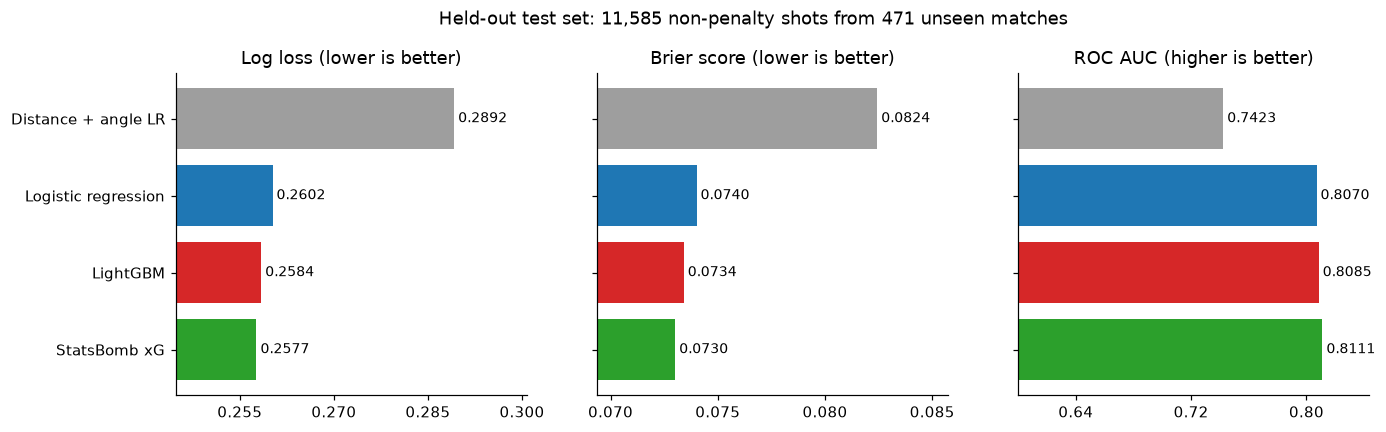

In [10]:
# Metric comparison chart
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
order = list(preds.columns)
for ax, (m, title, better) in zip(axes, [("log_loss", "Log loss", "lower is better"),
                                          ("brier", "Brier score", "lower is better"),
                                          ("roc_auc", "ROC AUC", "higher is better")]):
    vals = metrics.loc[order, m]
    ax.barh(order, vals, color=[PALETTE[o] for o in order])
    for i, v in enumerate(vals):
        ax.text(v, i, f" {v:.4f}", va="center", fontsize=9)
    lo = vals.min() * 0.95 if m != "roc_auc" else 0.6
    ax.set_xlim(lo, vals.max() * 1.04); ax.xaxis.set_major_locator(plt.MaxNLocator(4)); ax.set_title(f"{title} ({better})"); ax.invert_yaxis()
axes[1].set_yticklabels([]); axes[2].set_yticklabels([])
fig.suptitle(f"Held-out test set: {len(test):,} non-penalty shots from {test.match_id.nunique()} unseen matches",
             y=1.03)
save(fig, "02_model_comparison.png"); plt.show()

### Calibration

For xG, calibration matters as much as ranking: if a model says 0.20, roughly one in five such shots should
go in. The reliability diagram bins test shots by predicted xG (quantile bins) and compares the mean
prediction with the observed goal rate. The diagonal is perfect calibration.

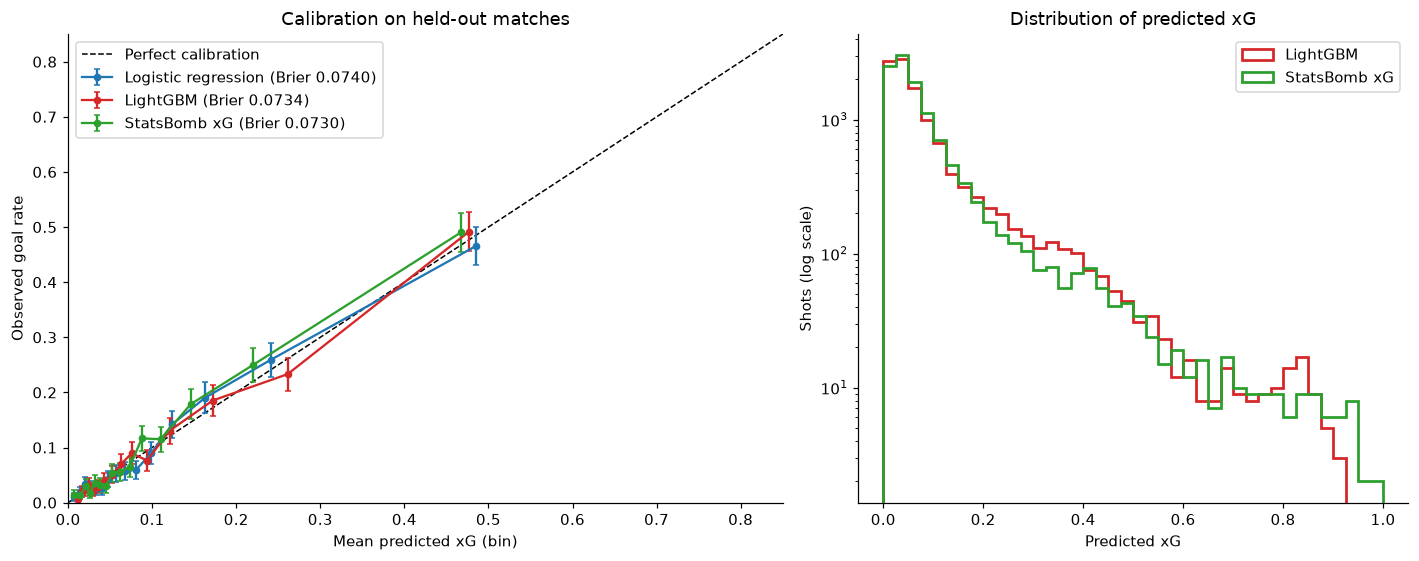

In [11]:
def reliability(y_true, p, n_bins=15):
    q = pd.qcut(p, n_bins, duplicates="drop")
    g = pd.DataFrame({"y": y_true, "p": p, "b": q}).groupby("b", observed=True)
    out = g.agg(pred=("p", "mean"), obs=("y", "mean"), n=("y", "size"))
    out["se"] = np.sqrt(out.obs * (1 - out.obs) / out.n)
    return out

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
for name in ["Logistic regression", "LightGBM", "StatsBomb xG"]:
    r = reliability(yt, preds[name].values)
    ax.errorbar(r.pred, r.obs, yerr=1.96 * r.se, fmt="o-", ms=4, capsize=2, color=PALETTE[name],
                label=f"{name} (Brier {metrics.loc[name, 'brier']:.4f})")
ax.set(xlabel="Mean predicted xG (bin)", ylabel="Observed goal rate", xlim=(0, 0.85), ylim=(0, 0.85),
       title="Calibration on held-out matches")
ax.legend(loc="upper left")
ax = axes[1]
bins = np.linspace(0, 1, 41)
for name in ["LightGBM", "StatsBomb xG"]:
    ax.hist(preds[name], bins=bins, histtype="step", lw=1.8, color=PALETTE[name], label=name)
ax.set_yscale("log"); ax.set(xlabel="Predicted xG", ylabel="Shots (log scale)",
                             title="Distribution of predicted xG"); ax.legend()
fig.tight_layout(); save(fig, "03_calibration.png"); plt.show()

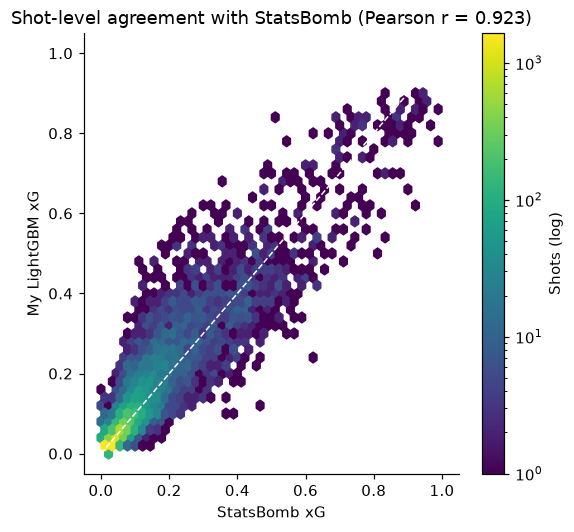

Pearson correlation with StatsBomb xG on test shots: 0.923


In [12]:
# How closely does my model agree with StatsBomb's professional model, shot by shot?
corr = np.corrcoef(preds["LightGBM"], preds["StatsBomb xG"])[0, 1]
fig, ax = plt.subplots(figsize=(5.5, 5.2))
hb = ax.hexbin(preds["StatsBomb xG"], preds["LightGBM"], gridsize=45, bins="log", cmap="viridis",
               extent=(0, 1, 0, 1), mincnt=1)
ax.plot([0, 1], [0, 1], "w--", lw=1)
ax.set(xlabel="StatsBomb xG", ylabel="My LightGBM xG",
       title=f"Shot-level agreement with StatsBomb (Pearson r = {corr:.3f})")
fig.colorbar(hb, ax=ax, label="Shots (log)")
save(fig, "04_vs_statsbomb.png"); plt.show()
print(f"Pearson correlation with StatsBomb xG on test shots: {corr:.3f}")

### Generalisation check: train on club football, test on international tournaments

A stricter test than a random match split: fit on club competitions only and evaluate on the six
international tournaments (World Cups, Euros, Copa América, AFCON). Different teams, players, era and
tournament conditions.

In [13]:
club, intl = np_shots[np_shots.international == 0], np_shots[np_shots.international == 1]
c_fit_i, c_val_i = next(GroupShuffleSplit(1, test_size=0.15, random_state=SEED)
                        .split(club, club.is_goal, club.match_id))
gbm_c = lgb.LGBMClassifier(**lgb_params).fit(
    club.iloc[c_fit_i][FEATURES], club.iloc[c_fit_i].is_goal,
    eval_set=[(club.iloc[c_val_i][FEATURES], club.iloc[c_val_i].is_goal)],
    callbacks=[lgb.early_stopping(100, verbose=False)])
lr_c = make_lr(NUM, BIN, CAT).fit(club, club.is_goal)
yi = intl.is_goal.values
gen = pd.DataFrame([
    {"model": n, "log_loss": log_loss(yi, p), "brier": brier_score_loss(yi, p),
     "roc_auc": roc_auc_score(yi, p), "total_xG": p.sum(), "actual_goals": yi.sum()}
    for n, p in [("Logistic regression", lr_c.predict_proba(intl)[:, 1]),
                 ("LightGBM", gbm_c.predict_proba(intl[FEATURES], num_iteration=gbm_c.best_iteration_)[:, 1]),
                 ("StatsBomb xG", intl.statsbomb_xg.values)]]).set_index("model")
print(f"Train: {len(club):,} club shots. Test: {len(intl):,} international-tournament shots "
      f"from {intl.match_id.nunique()} matches")
gen.to_csv(os.path.join(RES_DIR, "club_to_international_metrics.csv"))
gen.round(4)

Train: 50,155 club shots. Test: 7,509 international-tournament shots from 314 matches


,log_loss,brier,roc_auc,total_xG,actual_goals
model,,,,,
Logistic regression,0.2475,0.0689,0.7944,728.3647,668
LightGBM,0.2462,0.0686,0.7931,732.9533,668
StatsBomb xG,0.2442,0.0677,0.7962,686.5588,668


## 6. What does the model rely on?

SHAP values break each prediction into additive contributions from each feature, so we can see both how
important a feature is and in which direction it pushes xG.

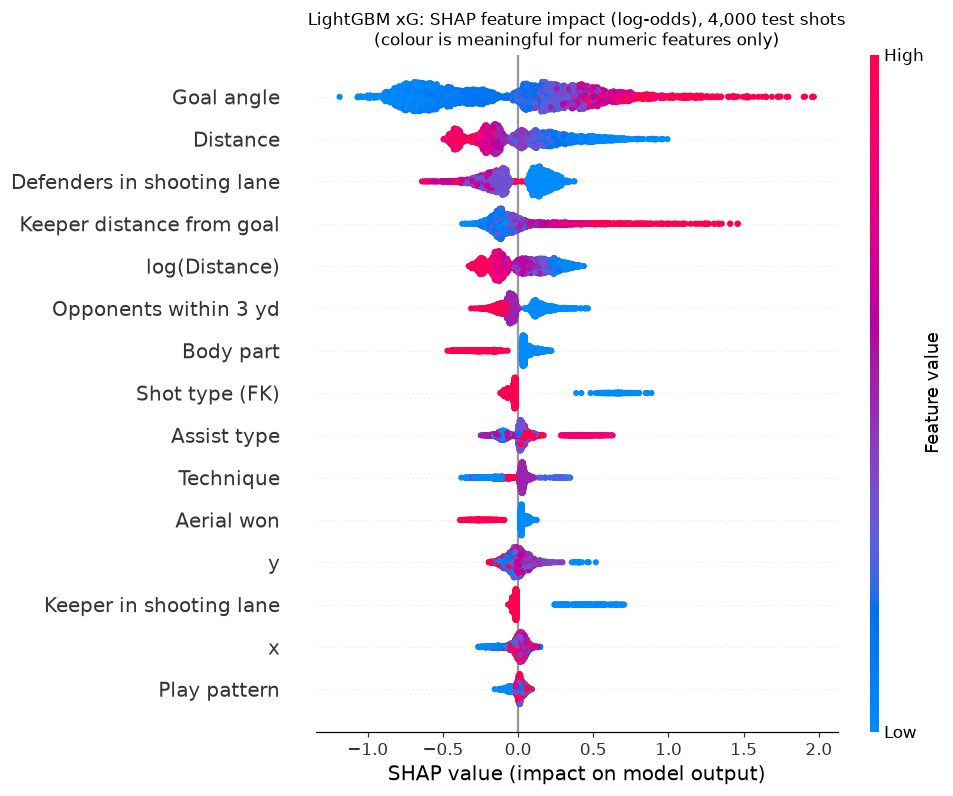

angle              0.473
distance           0.240
n_def_in_cone      0.175
gk_dist_to_goal    0.160
log_distance       0.156
n_opp_within_3     0.104
body_group         0.096
shot_type          0.079
assist_type        0.074
technique          0.062
Name: mean_abs_shap, dtype: float64

In [14]:
sample = test.sample(4000, random_state=SEED)
explainer = shap.TreeExplainer(gbm)
sv = explainer.shap_values(sample[FEATURES])
sv = sv[1] if isinstance(sv, list) else sv
X_disp = sample[FEATURES].copy()
for c in CAT:   # categorical colours are arbitrary codes; read these rows by spread, not colour
    X_disp[c] = X_disp[c].cat.codes
NICE = {"angle": "Goal angle", "distance": "Distance", "log_distance": "log(Distance)",
        "n_def_in_cone": "Defenders in shooting lane", "gk_dist_to_goal": "Keeper distance from goal",
        "n_opp_within_3": "Opponents within 3 yd", "body_group": "Body part", "shot_type": "Shot type (FK)",
        "assist_type": "Assist type", "technique": "Technique", "aerial_won": "Aerial won",
        "gk_in_cone": "Keeper in shooting lane", "play_pattern": "Play pattern", "x": "x", "y": "y",
        "under_pressure": "Under pressure", "first_time": "First time", "one_on_one": "One-on-one",
        "open_goal": "Open goal", "follows_dribble": "Follows dribble", "has_freeze_frame": "Has freeze frame"}
X_disp.columns = [NICE[c] for c in FEATURES]

fig = plt.figure(figsize=(9, 7))
shap.summary_plot(sv, X_disp, max_display=15, show=False, plot_size=None)
plt.title("LightGBM xG: SHAP feature impact (log-odds), 4,000 test shots\n"
          "(colour is meaningful for numeric features only)", fontsize=11)
save(plt.gcf(), "05_shap_summary.png"); plt.show()

imp = (pd.Series(np.abs(sv).mean(0), index=FEATURES).sort_values(ascending=False)
       .rename("mean_abs_shap"))
imp.to_csv(os.path.join(RES_DIR, "shap_importance.csv"))
imp.head(10).round(3)

In [15]:
# Interpretable view: odds ratios from the full logistic regression for the binary/categorical features
lr = lr_full.named_steps["lr"]; names = lr_full.named_steps["pre"].get_feature_names_out()
coefs = pd.Series(lr.coef_[0], index=[n.split("__", 1)[1] for n in names])
odds = np.exp(coefs).rename("odds_ratio")
# One-hot categories have no dropped reference level, so compare levels within a group via ratios
print(f"Header vs footed shot, odds ratio: {odds['body_group_Head'] / odds['body_group_Foot']:.2f}")
print(f"Through ball vs ground/low pass assist: {odds['assist_type_Through ball'] / odds['assist_type_Ground/low pass']:.2f}")
print(f"Cross vs ground/low pass assist: {odds['assist_type_Cross'] / odds['assist_type_Ground/low pass']:.2f}")
odds.loc[[c for c in odds.index if c in BIN or c.startswith(("body_group", "assist_type", "technique_"))]] \
    .sort_values().round(2).to_frame()

Header vs footed shot, odds ratio: 0.44
Through ball vs ground/low pass assist: 1.64
Cross vs ground/low pass assist: 0.81


,odds_ratio
technique_Backheel,0.42
has_freeze_frame,0.48
technique_Overhead Kick,0.55
body_group_Other,0.59
body_group_Head,0.60
aerial_won,0.60
assist_type_High pass,0.68
technique_Half Volley,0.71
assist_type_Cross,0.72
technique_Volley,0.82


## 7. Football analysis: who finishes above or below expectation?

To evaluate players fairly every shot needs an **out-of-sample** xG, so I re-fit the LightGBM model with
5-fold `GroupKFold` by match and predict each fold from models that never saw that match.

Goals minus xG is noisy. To separate skill from luck, I also report a z-score:
(goals − xG) / √Σ xG(1 − xG), the number of standard deviations a player's goal tally is from what an
average finisher would score on the same shots (treating shots as independent Bernoulli trials).
Minimum 60 non-penalty shots.

In [16]:
oof = np.zeros(len(np_shots))
for k, (tr, te) in enumerate(GroupKFold(n_splits=5).split(np_shots, y, groups)):
    m = lgb.LGBMClassifier(**{**lgb_params, "n_estimators": BEST_ITER})
    m.fit(np_shots.iloc[tr][FEATURES], y[tr])
    oof[te] = m.predict_proba(np_shots.iloc[te][FEATURES])[:, 1]
np_shots["xg"] = oof
print(f"Out-of-fold log loss {log_loss(y, oof):.4f}, AUC {roc_auc_score(y, oof):.4f} "
      f"(StatsBomb on same shots: {log_loss(y, np_shots.statsbomb_xg):.4f}, "
      f"{roc_auc_score(y, np_shots.statsbomb_xg):.4f})")
np_shots[["shot_id", "match_id", "competition", "team", "player", "x", "y", "is_goal",
          "xg", "statsbomb_xg"]].to_csv(os.path.join(RES_DIR, "shots_with_xg.csv"), index=False)

Out-of-fold log loss 0.2604, AUC 0.8096 (StatsBomb on same shots: 0.2604, 0.8109)


In [17]:
MIN_SHOTS = 60
players = (np_shots.assign(var=np_shots.xg * (1 - np_shots.xg))
           .groupby(["player_id", "player"])
           .agg(team=("team", lambda s: s.value_counts().index[0]), shots=("is_goal", "size"),
                goals=("is_goal", "sum"), xg=("xg", "sum"), sb_xg=("statsbomb_xg", "sum"), var=("var", "sum"))
           .reset_index())
players = players[players.shots >= MIN_SHOTS].copy()
players["goals_minus_xg"] = players.goals - players.xg
players["goals_minus_sb_xg"] = players.goals - players.sb_xg
players["xg_per_shot"] = players.xg / players.shots
players["z"] = players.goals_minus_xg / np.sqrt(players["var"])
players = players.drop(columns=["var", "player_id"]).sort_values("goals_minus_xg", ascending=False)
players.to_csv(os.path.join(RES_DIR, "player_finishing.csv"), index=False)
print(f"{len(players)} players with at least {MIN_SHOTS} non-penalty shots")
cols = ["player", "team", "shots", "goals", "xg", "goals_minus_xg", "z", "goals_minus_sb_xg"]
print("Top over-performers"); display(players[cols].head(10).round(2))
print("Top under-performers"); display(players[cols].tail(10).iloc[::-1].round(2))

183 players with at least 60 non-penalty shots
Top over-performers


,player,team,shots,goals,xg,goals_minus_xg,z,goals_minus_sb_xg
749,Lionel Messi,Barcelona,2335,417,316.49,100.51,6.71,146.20
691,Luis Suárez,Barcelona,621,131,111.18,19.82,2.33,28.10
2260,Samuel Eto'o,Barcelona,298,62,52.13,9.87,1.74,15.24
402,Zlatan Ibrahimović,Paris Saint-Germain,224,44,34.29,9.71,2.02,15.47
746,Gonzalo Higuaín,Napoli,193,35,25.90,9.10,2.09,10.95
729,Ousmane Dembélé,Barcelona,176,27,18.02,8.98,2.41,10.49
723,Ivan Rakitić,Barcelona,226,26,17.49,8.51,2.28,8.58
234,Alexis Sánchez,Barcelona,233,42,33.77,8.23,1.72,11.75
149,Sergio Agüero,Manchester City,141,27,19.14,7.86,2.10,9.57
999,Gareth Bale,Real Madrid,105,20,12.35,7.65,2.58,9.19


Top under-performers


,player,team,shots,goals,xg,goals_minus_xg,z,goals_minus_sb_xg
547,Martin Braithwaite,Toulouse,164,14,24.32,-10.32,-2.52,-8.71
665,Andrés Iniesta,Barcelona,363,24,31.25,-7.25,-1.49,-4.39
1290,Edin Džeko,AS Roma,86,6,12.44,-6.44,-2.26,-5.90
796,Carlos Vela,Real Sociedad,82,6,11.95,-5.95,-2.17,-4.56
491,Aleksandar Mitrović,Newcastle United,114,10,15.84,-5.84,-1.74,-5.21
1097,Giampaolo Pazzini,Hellas Verona,76,3,8.05,-5.05,-2.06,-4.43
24,Memphis Depay,Manchester United,95,5,10.00,-5.00,-1.85,-3.91
272,Michy Batshuayi,Olympique de Marseille,138,17,21.67,-4.67,-1.21,-3.44
52,Andy Delort,Stade Malherbe Caen,138,8,12.37,-4.37,-1.42,-2.30
1463,Andrea Belotti,Torino,78,8,12.30,-4.30,-1.54,-3.13


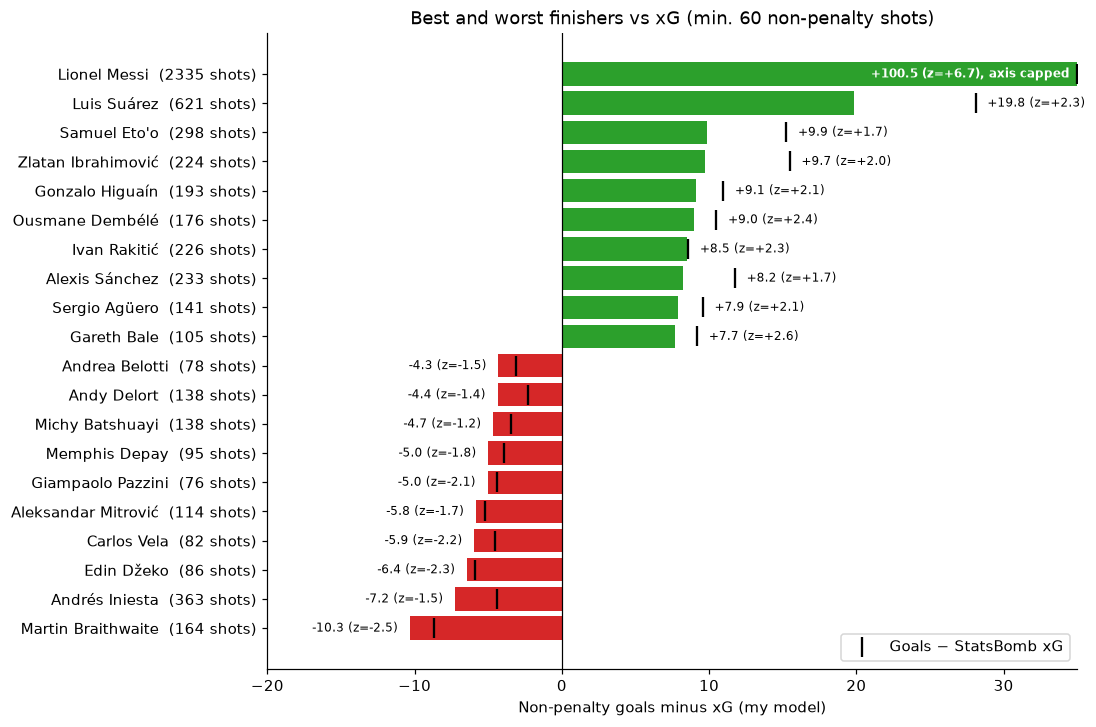

In [18]:
top = pd.concat([players.head(10), players.tail(10)]).sort_values("goals_minus_xg").reset_index(drop=True)
CAP = 35   # Messi's tally is so large it would flatten every other bar, so the axis is capped
fig, ax = plt.subplots(figsize=(9.5, 7.5))
vals = top.goals_minus_xg.clip(upper=CAP)
ax.barh(top.player + "  (" + top.shots.astype(str) + " shots)", vals,
        color=np.where(top.goals_minus_xg > 0, "#2ca02c", "#d62728"))
ax.scatter(top.goals_minus_sb_xg.clip(upper=CAP), np.arange(len(top)), marker="|", s=180,
           color="black", label="Goals − StatsBomb xG", zorder=3)
ax.axvline(0, color="black", lw=0.8)
for i, r in top.iterrows():
    lab = f"{r.goals_minus_xg:+.1f} (z={r.z:+.1f})"
    if r.goals_minus_xg > CAP:
        lab = f"{r.goals_minus_xg:+.1f} (z={r.z:+.1f}), axis capped"
        ax.text(CAP - 0.5, i, lab, va="center", ha="right", fontsize=8, color="white", fontweight="bold")
    elif r.goals_minus_xg > 0:
        ax.text(max(r.goals_minus_xg, r.goals_minus_sb_xg) + 0.8, i, lab, va="center", fontsize=8)
    else:
        ax.text(min(r.goals_minus_xg, r.goals_minus_sb_xg) - 0.8, i, lab, va="center", ha="right", fontsize=8)
ax.set(xlabel="Non-penalty goals minus xG (my model)", xlim=(-20, CAP),
       title=f"Best and worst finishers vs xG (min. {MIN_SHOTS} non-penalty shots)")
ax.legend(loc="lower right")
save(fig, "06_finishing_over_under.png"); plt.show()

## 8. Visualising xG on the pitch

### Where are the high-quality chances?

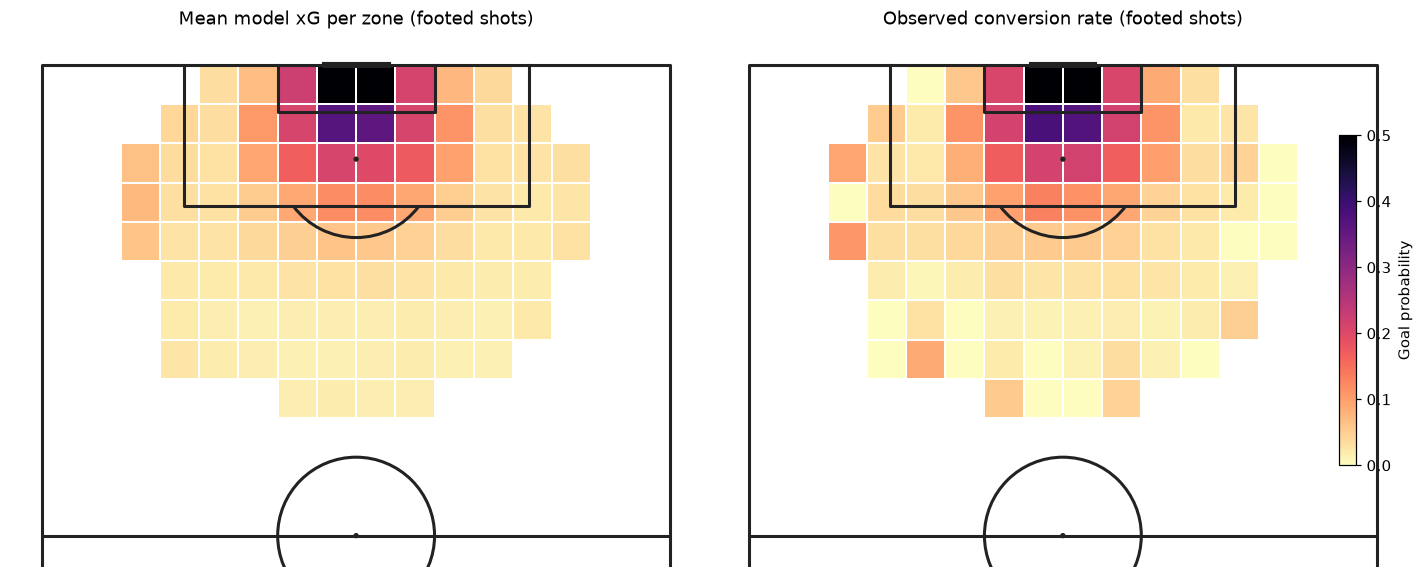

In [19]:
pitch = VerticalPitch(pitch_type="statsbomb", half=True, line_color="#222222", line_zorder=2)
fig, axes = pitch.draw(nrows=1, ncols=2, figsize=(13, 6))
footed = np_shots[np_shots.body_group == "Foot"]
for ax, (col, title) in zip(axes, [("xg", "Mean model xG per zone (footed shots)"),
                                    ("is_goal", "Observed conversion rate (footed shots)")]):
    stat = pitch.bin_statistic(footed.x, footed.y, values=footed[col], statistic="mean", bins=(24, 16))
    cnt = pitch.bin_statistic(footed.x, footed.y, statistic="count", bins=(24, 16))
    stat["statistic"] = np.where(cnt["statistic"] >= 15, stat["statistic"], np.nan)  # hide sparse zones
    hm = pitch.heatmap(stat, ax=ax, cmap="magma_r", vmin=0, vmax=0.5, edgecolors="white", lw=0.3)
    ax.set_title(title, fontsize=12)
cax = fig.add_axes([0.94, 0.25, 0.012, 0.5])
fig.colorbar(hm, cax=cax, label="Goal probability")
save(fig, "07_xg_surface.png"); plt.show()

### Shot map: 2022 World Cup final, Argentina 3-3 France (Argentina won on penalties)

Marker size is my model's xG; filled markers are goals. In-game penalties are valued at the observed
in-game conversion rate. The shoot-out is excluded.

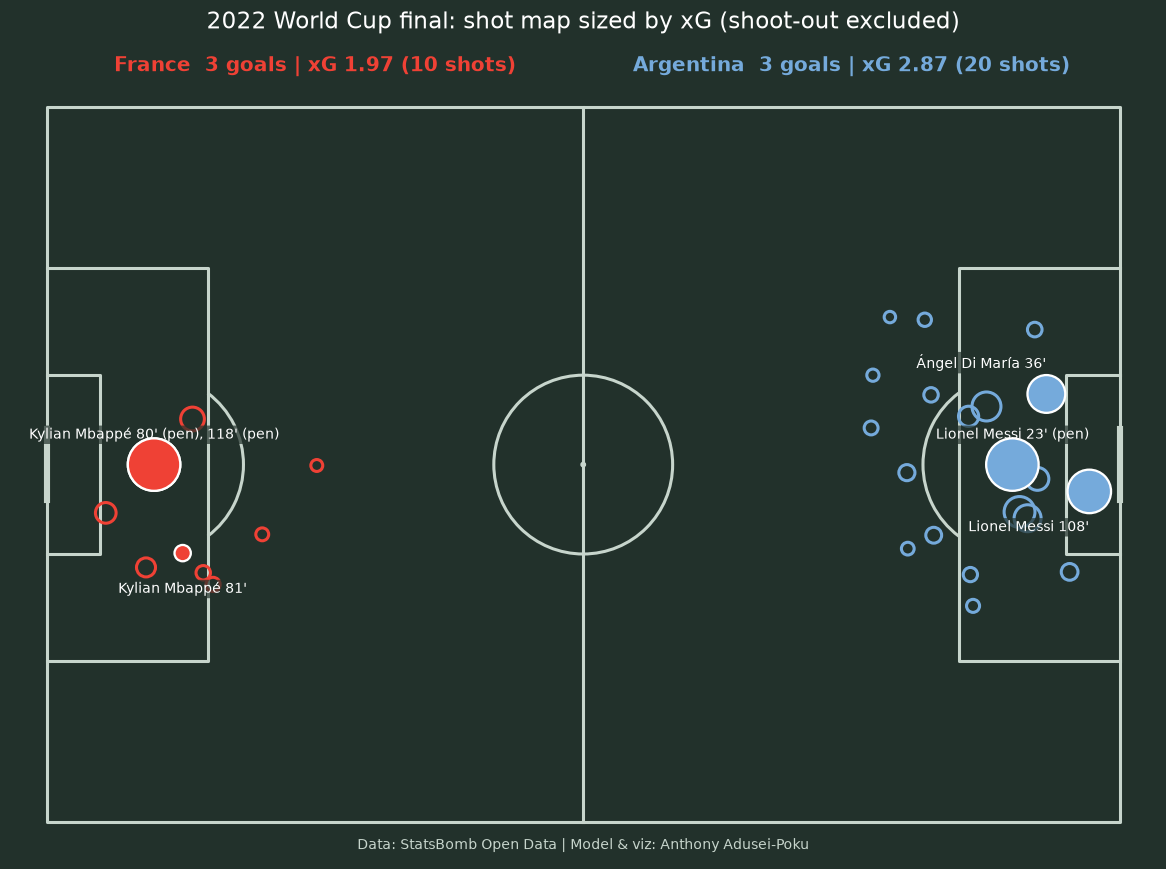

,shots,goals,xg,sb
team,,,,
Argentina,20,3,2.87,2.76
France,10,3,1.97,2.27


In [20]:
final = shots[(shots.competition == "FIFA World Cup 2022") & (shots.match_date == "2022-12-18")
              & (shots.period < 5)].copy()
# Use the out-of-fold prediction for each shot so the model never saw this match when scoring it
final["xg"] = final.shot_id.map(np_shots.set_index("shot_id").xg)
final.loc[final.shot_type == "Penalty", "xg"] = PEN_XG

pitch = Pitch(pitch_type="statsbomb", line_color="#c7d5cc", pitch_color="#22312b")
fig, ax = pitch.draw(figsize=(12, 8))
fig.set_facecolor("#22312b")
team_cols = {"Argentina": "#75aadb", "France": "#ef4135"}
for team, col in team_cols.items():
    t = final[final.team == team]
    xs = t.x if team == "Argentina" else 120 - t.x   # Argentina attack right, France left
    ys = t.y if team == "Argentina" else 80 - t.y
    goal = t.is_goal == 1
    pitch.scatter(xs[~goal], ys[~goal], s=t.xg[~goal] * 1500 + 40, ax=ax, facecolors="none",
                  edgecolors=col, lw=2, zorder=3)
    pitch.scatter(xs[goal], ys[goal], s=t.xg[goal] * 1500 + 40, ax=ax, c=col, edgecolors="white",
                  lw=1.5, zorder=4)
    # Label goals (minute + 1 gives the conventional match minute; group goals from the same spot)
    lab = t[goal].assign(xx=xs[goal], yy=ys[goal],
                         m=lambda d: (d.minute + 1).astype(str) + "'" + np.where(d.shot_type == "Penalty", " (pen)", ""))
    for (xx, yy), grp in lab.groupby(["xx", "yy"]):
        ha = "right" if xx > 110 else ("left" if xx < 10 else "center")
        ax.annotate(f"{grp.player.iloc[0]} " + ", ".join(grp.m), (xx, yy), xytext=(0, 17 if yy <= 41 else -26),
                    textcoords="offset points", ha=ha, color="white", fontsize=9,
                    bbox=dict(boxstyle="round,pad=0.15", fc="#22312b", ec="none", alpha=0.7))
summ = final.groupby("team").agg(shots=("is_goal", "size"), goals=("is_goal", "sum"),
                                 xg=("xg", "sum"), sb=("statsbomb_xg", "sum"))
ax.text(30, -4, f"France  {summ.loc['France','goals']} goals | xG {summ.loc['France','xg']:.2f} "
        f"({summ.loc['France','shots']} shots)", color=team_cols["France"], ha="center", fontsize=13,
        fontweight="bold")
ax.text(90, -4, f"Argentina  {summ.loc['Argentina','goals']} goals | xG {summ.loc['Argentina','xg']:.2f} "
        f"({summ.loc['Argentina','shots']} shots)", color=team_cols["Argentina"], ha="center",
        fontsize=13, fontweight="bold")
ax.set_title("2022 World Cup final: shot map sized by xG (shoot-out excluded)", color="white",
             fontsize=15, pad=28)
ax.text(60, 83, "Data: StatsBomb Open Data | Model & viz: Anthony Adusei-Poku", color="#c7d5cc",
        ha="center", fontsize=9)
save(fig, "08_shotmap_wc2022_final.png"); plt.show()
summ.round(2)

### Shot map: Lionel Messi across the StatsBomb La Liga collection

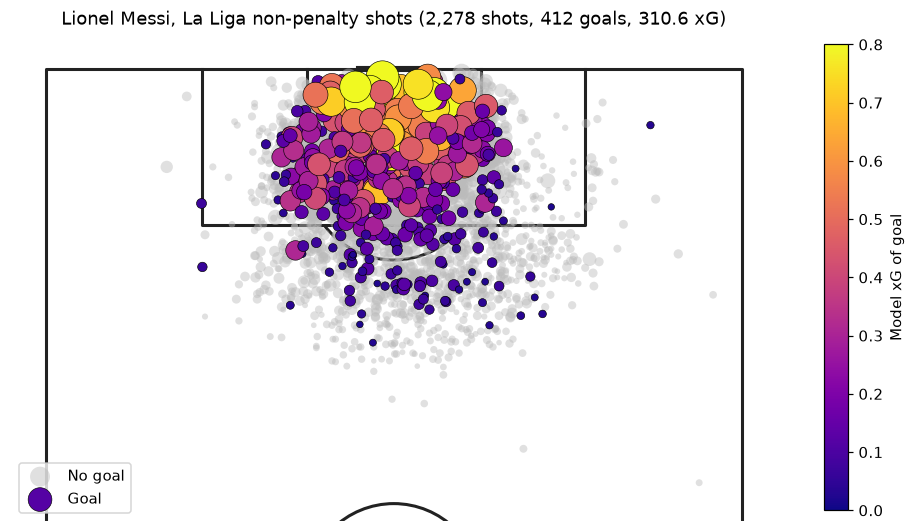

In [21]:
messi = np_shots[(np_shots.player == "Lionel Messi")
                 & np_shots.competition.str.startswith("La Liga")]
pitch = VerticalPitch(pitch_type="statsbomb", half=True, line_color="#222222", pad_bottom=-8)
fig, ax = pitch.draw(figsize=(9, 8))
g = messi.is_goal == 1
sc = pitch.scatter(messi.x[~g], messi.y[~g], s=messi.xg[~g] * 500 + 8, c="#bbbbbb", alpha=0.45, ax=ax,
                   edgecolors="none", label="No goal")
sc2 = pitch.scatter(messi.x[g], messi.y[g], s=messi.xg[g] * 500 + 8, c=messi.xg[g], cmap="plasma",
                    vmin=0, vmax=0.8, ax=ax, edgecolors="black", lw=0.4, label="Goal")
fig.colorbar(sc2, ax=ax, shrink=0.55, label="Model xG of goal")
ax.set_title(f"Lionel Messi, La Liga non-penalty shots ({len(messi):,} shots, {int(messi.is_goal.sum())} goals, "
             f"{messi.xg.sum():.1f} xG)", fontsize=12)
ax.legend(loc="lower left")
save(fig, "09_shotmap_messi.png"); plt.show()

## 9. Conclusions

* On 11,585 held-out non-penalty shots from 471 unseen matches, the LightGBM model reached **log loss 0.2584, Brier 0.0734 and ROC AUC 0.809**, against **0.2577 / 0.0730 / 0.811 for StatsBomb's professional xG**. The paired bootstrap difference in log loss (+0.0008, 95% CI −0.0019 to +0.0034) is not statistically distinguishable from zero.
* Adding technique, assist and freeze-frame features to the two-feature distance/angle model cut log loss by 10% (0.2892 → 0.2602) and lifted AUC from 0.742 to 0.807.
* My model is better calibrated in aggregate on this data: 1,157 xG for 1,159 actual goals on the test set, compared with 1,084 for StatsBomb xG.
* Trained only on club football, the model transferred to international tournaments with log loss 0.2462 (StatsBomb 0.2442).
* Goal angle, distance, defenders in the shooting lane and goalkeeper position are the most important features (SHAP).
* Messi's finishing (+100.5 goals above my xG on 2,335 shots, z = +6.7) is the only over-performance in the data that is far beyond what luck would plausibly produce.

**Limitations**
* Freeze frames record visible players only; off-camera defenders and goalkeeper position can be missing.
* The dataset is not a random sample of football: the La Liga collection follows Barcelona (Messi) matches, and 2015/16 dominates the club data.
* No information on shot speed, the shooter's weaker foot or body shape, which professional models such as StatsBomb's partly capture.
* Goals-minus-xG mixes finishing skill with luck. Even large over-performance is only a few standard deviations from zero.

**Next steps**
* Add weaker-foot and shooter-position features; experiment with the 360 data for more seasons.
* Post-shot xG (using shot end location) to evaluate goalkeepers.
* Bayesian shrinkage of finishing skill (beta-binomial) to rank finishers more robustly.